In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import pickle

print("✅ Libraries imported!")

✅ Libraries imported!


In [2]:
df = pd.read_csv(r'D:\Projects\log-anomaly-detector\network_logs.csv')
print("Shape:", df.shape)
df.head()

Shape: (1000, 9)


,timestamp,ip_address,user_id,action,bytes_transferred,response_time_ms,failed_attempts,hour,is_anomaly
0,2024-01-01 08:34:35,192.168.1.14,user_1,LOGIN_SUCCESS,4436,419,1,8,0
1,2024-01-01 08:37:50,192.168.1.16,user_45,PASSWORD_CHANGE,1369,240,0,8,0
2,2024-01-01 08:42:22,192.168.1.11,user_31,LOGOUT,4528,189,1,8,0
3,2024-01-01 09:12:57,192.168.1.15,user_9,LOGIN_SUCCESS,2816,112,0,9,0
4,2024-01-01 09:14:08,192.168.1.5,user_45,FILE_ACCESS,2618,114,0,9,0


In [3]:
print("Normal vs Anomaly:")
print(df['is_anomaly'].value_counts())
print(f"\nAnomaly Rate: {df['is_anomaly'].mean()*100:.1f}%")
print("\nActions found:")
print(df['action'].value_counts())

Normal vs Anomaly:
is_anomaly
0    900
1    100
Name: count, dtype: int64

Anomaly Rate: 10.0%

Actions found:
action
PASSWORD_CHANGE          201
FILE_ACCESS              181
LOGOUT                   180
LOGIN_SUCCESS            175
DATA_READ                163
PORT_SCAN                 26
DATA_EXFILTRATION         23
BRUTE_FORCE_ATTEMPT       21
PRIVILEGE_ESCALATION      16
MULTIPLE_FAILED_LOGIN     14
Name: count, dtype: int64


In [4]:
le_ip = LabelEncoder()
le_action = LabelEncoder()
le_user = LabelEncoder()

df['ip_encoded'] = le_ip.fit_transform(df['ip_address'])
df['action_encoded'] = le_action.fit_transform(df['action'])
df['user_encoded'] = le_user.fit_transform(df['user_id'])

# Features for model
features = ['ip_encoded', 'action_encoded', 'user_encoded',
            'bytes_transferred', 'response_time_ms', 
            'failed_attempts', 'hour']

X = df[features]
print("✅ Features ready:", X.shape)
X.head()

✅ Features ready: (1000, 7)


,ip_encoded,action_encoded,user_encoded,bytes_transferred,response_time_ms,failed_attempts,hour
0,5,4,0,4436,419,1,8
1,7,7,39,1369,240,0,8
2,2,5,24,4528,189,1,8
3,6,4,49,2816,112,0,9
4,14,3,39,2618,114,0,9


In [5]:
model = IsolationForest(
    contamination=0.1,  # 10% expected anomalies
    random_state=42,
    n_estimators=100
)

model.fit(X)
print("✅ Model trained!")

✅ Model trained!


In [6]:
# Isolation Forest returns -1 for anomaly, 1 for normal
# Convert to 0/1 to match our labels
df['predicted'] = model.predict(X)
df['predicted'] = df['predicted'].map({1: 0, -1: 1})

print("Classification Report:")
print(classification_report(df['is_anomaly'], df['predicted']))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       900
           1       1.00      1.00      1.00       100

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



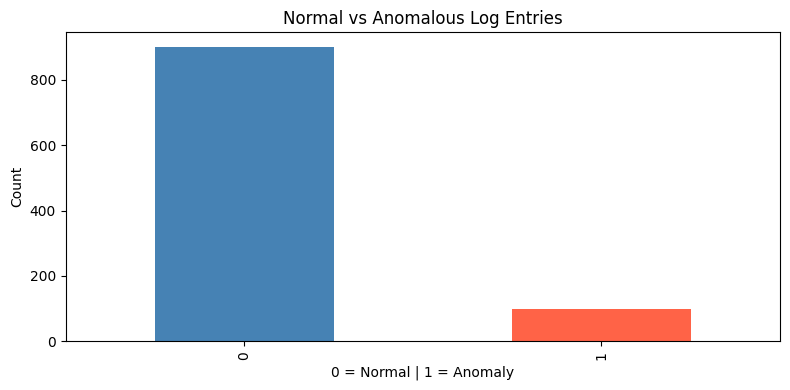

In [7]:
plt.figure(figsize=(8,4))
colors = ['steelblue', 'tomato']
df['predicted'].value_counts().plot(kind='bar', color=colors)
plt.title('Normal vs Anomalous Log Entries')
plt.xlabel('0 = Normal | 1 = Anomaly')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

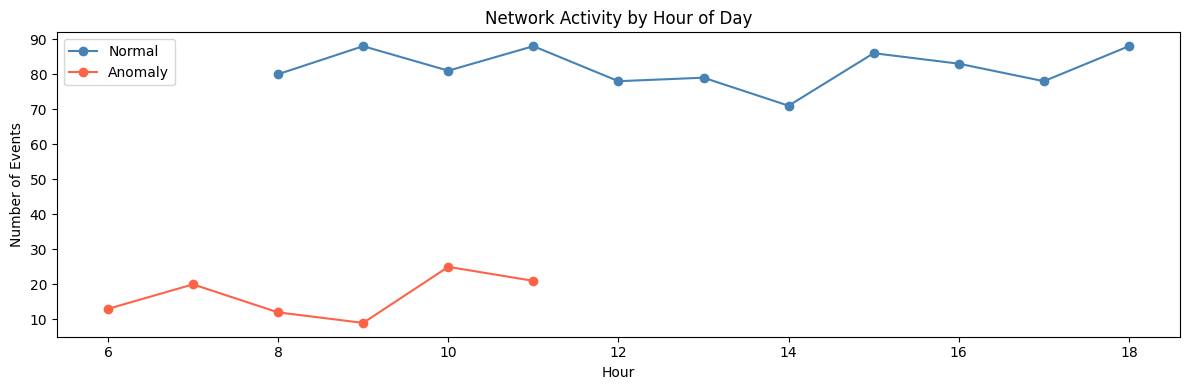

In [8]:
plt.figure(figsize=(12,4))
normal = df[df['predicted']==0].groupby('hour').size()
anomaly = df[df['predicted']==1].groupby('hour').size()

plt.plot(normal.index, normal.values, 
         label='Normal', color='steelblue', marker='o')
plt.plot(anomaly.index, anomaly.values, 
         label='Anomaly', color='tomato', marker='o')
plt.title('Network Activity by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Events')
plt.legend()
plt.tight_layout()
plt.show()

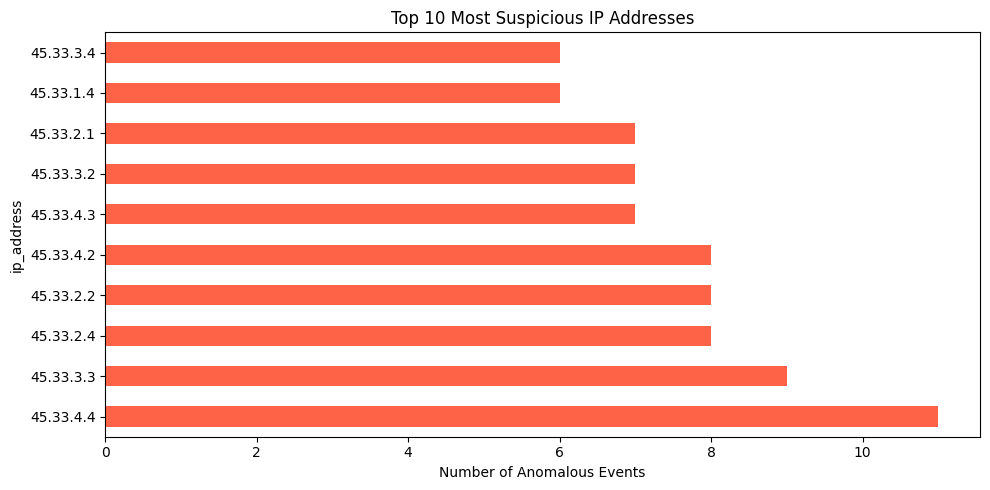

In [9]:
plt.figure(figsize=(10,5))
suspicious = df[df['predicted']==1]['ip_address'].value_counts().head(10)
suspicious.plot(kind='barh', color='tomato')
plt.title('Top 10 Most Suspicious IP Addresses')
plt.xlabel('Number of Anomalous Events')
plt.tight_layout()
plt.show()

In [10]:
pickle.dump(model, open(
    r'D:\Projects\log-anomaly-detector\anomaly_model.pkl', 'wb'))
pickle.dump(le_ip, open(
    r'D:\Projects\log-anomaly-detector\le_ip.pkl', 'wb'))
pickle.dump(le_action, open(
    r'D:\Projects\log-anomaly-detector\le_action.pkl', 'wb'))
pickle.dump(le_user, open(
    r'D:\Projects\log-anomaly-detector\le_user.pkl', 'wb'))
pickle.dump(features, open(
    r'D:\Projects\log-anomaly-detector\features.pkl', 'wb'))

print("✅ All models saved!")

✅ All models saved!
